# MFIN 4338 – Problem Set 1

Group number: …  
Names / student IDs: …

In [1]:
# ── Setup: libraries and display options ─────────────────────────────
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.stattools import jarque_bera
from IPython.display import display

%matplotlib inline
os.makedirs("figs", exist_ok=True)                     # folder for saved figures
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## Question 1 – Stock returns

#### (a) Import the data

In [2]:
# Read the sheet and use the date as index (sorted in time)
df = pd.read_excel("data/data_assignment1.xlsx", sheet_name="stock_monthly")
df = df.set_index("DATE").sort_index()

# Column names -> readable labels for plots and tables
names = {"VWRET": "VW index", "EWRET": "EW index", "COCACOLA": "Coca-Cola (KO)",
         "MICROSOFT": "Microsoft (MSFT)", "EXXON": "ExxonMobil (XOM)"}
cols = list(names)

print(df.shape, "| from", df.index.min().date(), "to", df.index.max().date())
df.head()

(420, 5) | from 1990-01-31 to 2024-12-31


,MICROSOFT,COCACOLA,EXXON,VWRET,EWRET
DATE,,,,,
1990-01-31,0.0632,-0.1084,-0.0600,-0.0701,-0.0464
1990-02-28,0.0676,0.0236,0.0128,0.0149,0.0154
1990-03-30,0.1215,0.0660,-0.0186,0.0241,0.0213
1990-04-30,0.0474,0.0201,-0.0190,-0.0283,-0.0281
1990-05-31,0.2586,0.1836,0.0740,0.0889,0.0457


#### (b) Simple returns → log returns

$r^{log}_t = \ln(1 + r^{simple}_t)$

In [3]:
# np.log1p(x) is simply log(1 + x), i.e. ln(1 + simple return) = log return
lr = np.log1p(df[cols])
lr.head()

,VWRET,EWRET,COCACOLA,MICROSOFT,EXXON
DATE,,,,,
1990-01-31,-0.0727,-0.0475,-0.1148,0.0613,-0.0619
1990-02-28,0.0148,0.0153,0.0233,0.0654,0.0127
1990-03-30,0.0239,0.0211,0.0639,0.1147,-0.0188
1990-04-30,-0.0287,-0.0285,0.0199,0.0463,-0.0192
1990-05-31,0.0852,0.0447,0.1686,0.2300,0.0714


#### (c) Simple vs log returns over time

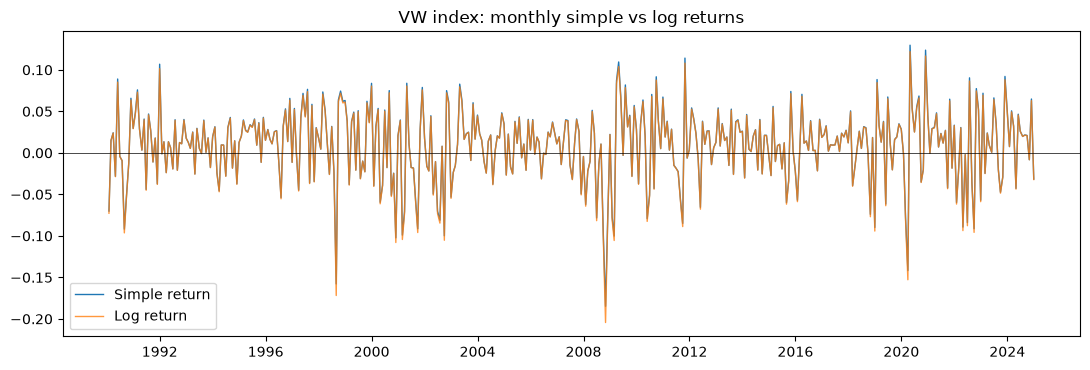

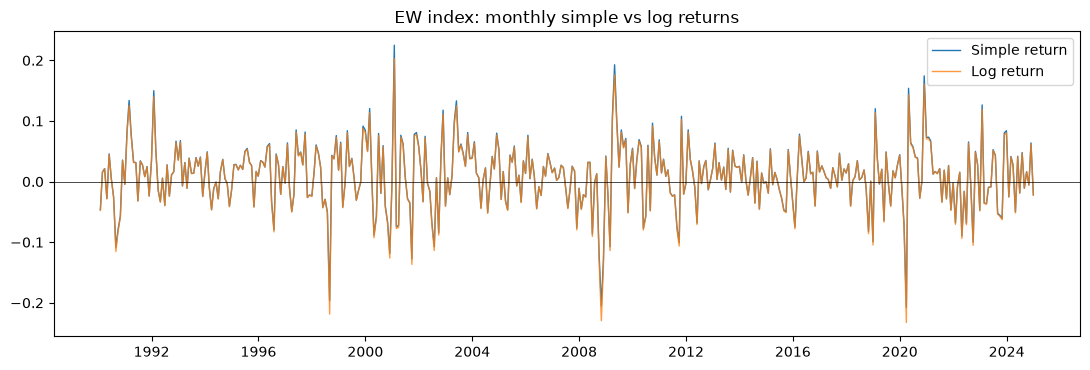

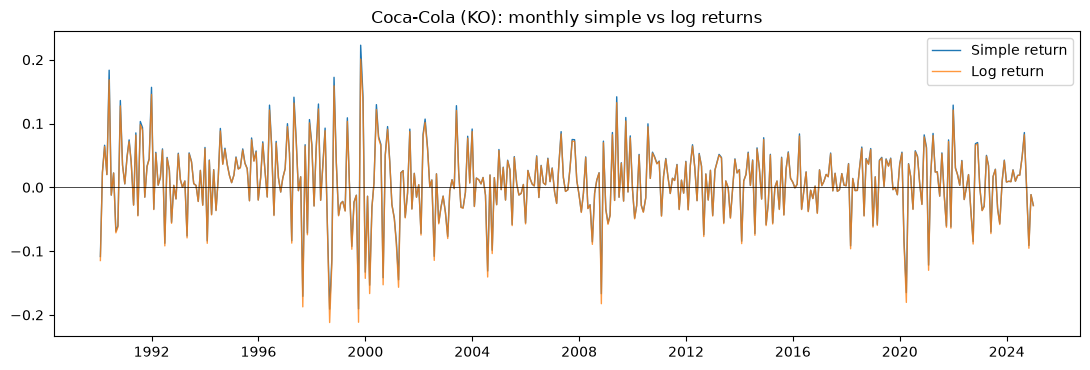

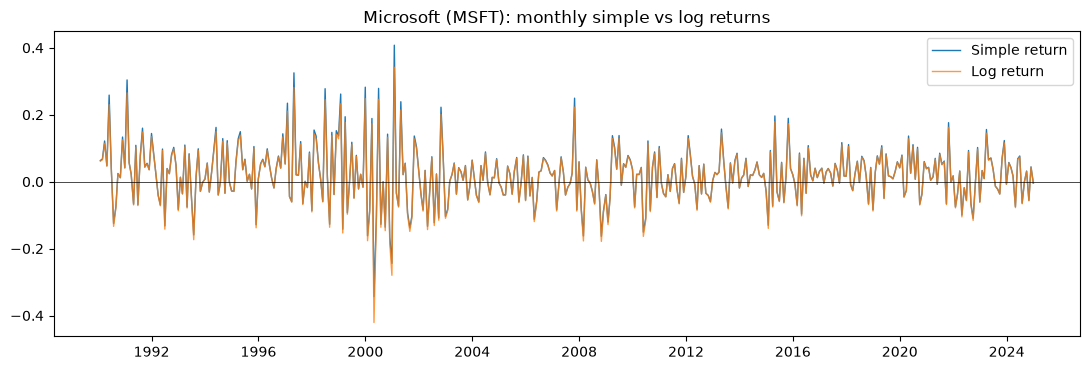

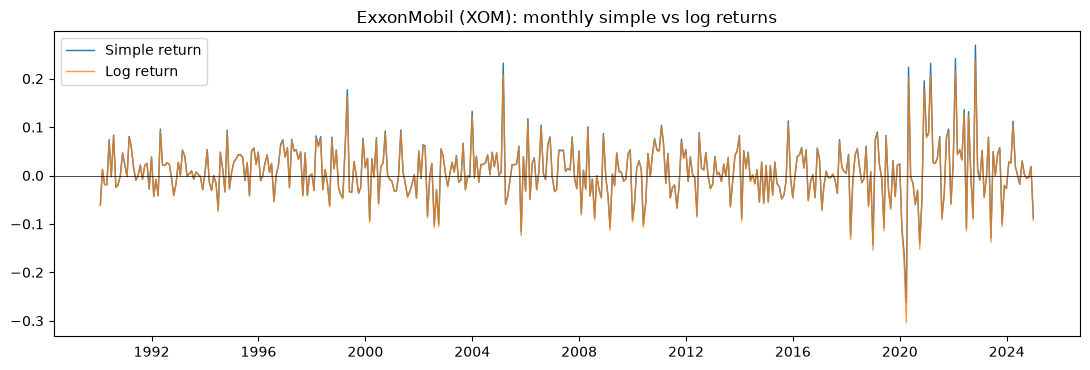

,max |simple - log|
VWRET,0.0195
EWRET,0.0251
COCACOLA,0.0217
MICROSOFT,0.0773
EXXON,0.0418


In [4]:
# One figure per series: the two lines almost coincide because monthly returns are small
for c in cols:
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.plot(df.index, df[c], lw=1, label="Simple return")
    ax.plot(lr.index, lr[c], lw=1, alpha=.8, label="Log return")
    ax.axhline(0, color="k", lw=.5)
    ax.set_title(f"{names[c]}: monthly simple vs log returns")
    ax.legend()
    fig.tight_layout()
    fig.savefig(f"figs/q1c_{c}.png", dpi=130)
    plt.show()

# Largest gap between simple and log return, per series
(df[cols] - lr).abs().max().rename("max |simple - log|").to_frame()

**Comment on the graphs**

- Simple and log returns are nearly identical, because monthly returns are small and ln(1+r) ≈ r.
- They differ only in extreme months: for large gains the log return is slightly *below* the simple return, for large losses it is *more negative* (e.g. Microsoft in 2000–01). The gap is largest for the single stocks and barely visible for the diversified indices.
- All series fluctuate around a small positive mean with no trend, as expected for returns.
- Volatility clustering: calm periods are interrupted by turbulent ones, e.g. 1998, 2008–09 and 2020 for the indices, the dot-com period for Microsoft, and 2020–22 for ExxonMobil.
- The single stocks, especially Microsoft, are clearly more volatile than the two indices, which reflects diversification.

#### (d) Correlation matrix of the log returns

In [5]:
lr.corr()

,VWRET,EWRET,COCACOLA,MICROSOFT,EXXON
VWRET,1.0000,0.8751,0.4359,0.5752,0.4887
EWRET,0.8751,1.0000,0.2810,0.4626,0.4106
COCACOLA,0.4359,0.2810,1.0000,0.2257,0.3219
MICROSOFT,0.5752,0.4626,0.2257,1.0000,0.1803
EXXON,0.4887,0.4106,0.3219,0.1803,1.0000


**Comment on the correlation matrix**

- Yes, all three stocks are positively correlated with both the value-weighted and the equal-weighted index, but to different degrees.
- Microsoft has the strongest correlation with both indices (VWRET and EWRET), Coca-Cola the lowest with both.
- The two indices are by far the most correlated with each other, which is expected since they are built from largely the same stocks.
- The lowest correlation in the whole matrix is between Microsoft and ExxonMobil, a technology and an energy company. The lowest correlation with an index is Coca-Cola with the equal-weighted index.
- The correlations between the stocks and the indices are positive but only moderate, and the stocks are also only weakly correlated with each other. A large part of each stock's movement is therefore firm-specific, which diversification removes in the indices.

#### (e) Scatterplots against the value-weighted index

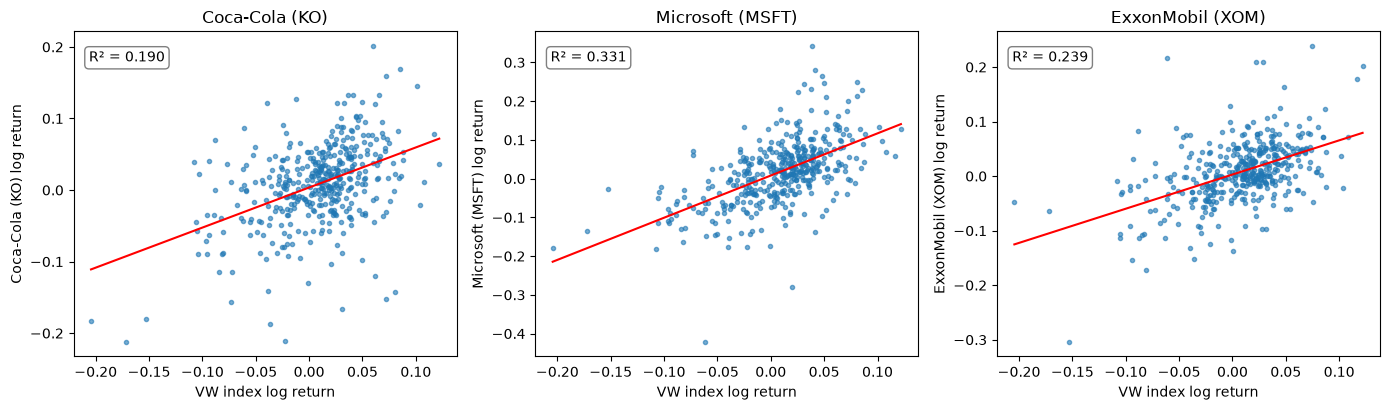

In [6]:
# Each stock vs the market, with an OLS line and its R²
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, c in zip(axs, ["COCACOLA", "MICROSOFT", "EXXON"]):
    ax.scatter(lr["VWRET"], lr[c], s=9, alpha=.6)
    slope, intercept = np.polyfit(lr["VWRET"], lr[c], 1)
    xs = np.linspace(lr["VWRET"].min(), lr["VWRET"].max(), 50)
    ax.plot(xs, intercept + slope * xs, "r")

    # R² of the line = squared correlation with the market (share of variance explained)
    r2 = lr["VWRET"].corr(lr[c]) ** 2
    ax.text(0.04, 0.94, f"R² = {r2:.3f}", transform=ax.transAxes, va="top",
            bbox=dict(boxstyle="round", fc="white", ec="grey"))

    ax.set_xlabel("VW index log return")
    ax.set_ylabel(f"{names[c]} log return")
    ax.set_title(names[c])
fig.tight_layout()
fig.savefig("figs/q1e_scatter.png", dpi=130)
plt.show()

**Comment on the scatterplots**

- For all three stocks the relationship with the value-weighted index is positive: the fitted line slopes upwards and the points cluster around it, in line with the positive correlations in (d).
- Coca-Cola shows the most scatter around the line (lowest R²), so the market explains the least of its movements.
- Microsoft is the least scattered (highest R²), with ExxonMobil in between, a bit more scattered than Microsoft.
- $R^2$ is the share of the variance of the stock's returns that is explained by the market return: $R^2 = 1 - \frac{SSR}{SST}$, which for a regression with one regressor equals the squared correlation, $R^2 = \text{corr}(r_{stock}, r_{VW})^2$.

#### (f) Descriptive statistics

In [7]:
# Variance uses n-1; kurtosis is *excess* kurtosis (Normal = 0)
desc = pd.DataFrame({
    "mean": lr.mean(),
    "variance": lr.var(),
    "std. dev.": lr.std(),
    "skewness": lr.apply(stats.skew),
    "excess kurtosis": lr.apply(stats.kurtosis),
    "min": lr.min(),
    "max": lr.max(),
}).T
desc

,VWRET,EWRET,COCACOLA,MICROSOFT,EXXON
mean,0.0080,0.0082,0.0080,0.0167,0.0079
variance,0.0020,0.0028,0.0033,0.0071,0.0032
std. dev.,0.0444,0.0530,0.0570,0.0840,0.0569
skewness,-0.8299,-0.5769,-0.5666,-0.1146,-0.0931
excess kurtosis,1.8272,2.7840,1.8697,2.4784,3.6548
min,-0.2044,-0.2326,-0.2119,-0.4209,-0.3036
max,0.1219,0.2030,0.2011,0.3420,0.2384


#### (g) t-test of H0: mean return = 0 (two-sided, 5%)

In [8]:
rows = []
for c in cols:
    t, p = stats.ttest_1samp(lr[c], 0.0)
    rows.append([names[c], lr[c].mean(), t, p, "Reject H0" if p < .05 else "Do not reject"])
pd.DataFrame(rows, columns=["series", "mean", "t-stat", "p-value", "decision (5%)"])

,series,mean,t-stat,p-value,decision (5%)
0,VW index,0.0080,3.7031,0.0002,Reject H0
1,EW index,0.0082,3.1815,0.0016,Reject H0
2,Coca-Cola (KO),0.0080,2.8927,0.0040,Reject H0
3,Microsoft (MSFT),0.0167,4.0874,0.0001,Reject H0
4,ExxonMobil (XOM),0.0079,2.8554,0.0045,Reject H0


#### (h) Histograms with fitted Normal density + Jarque–Bera test

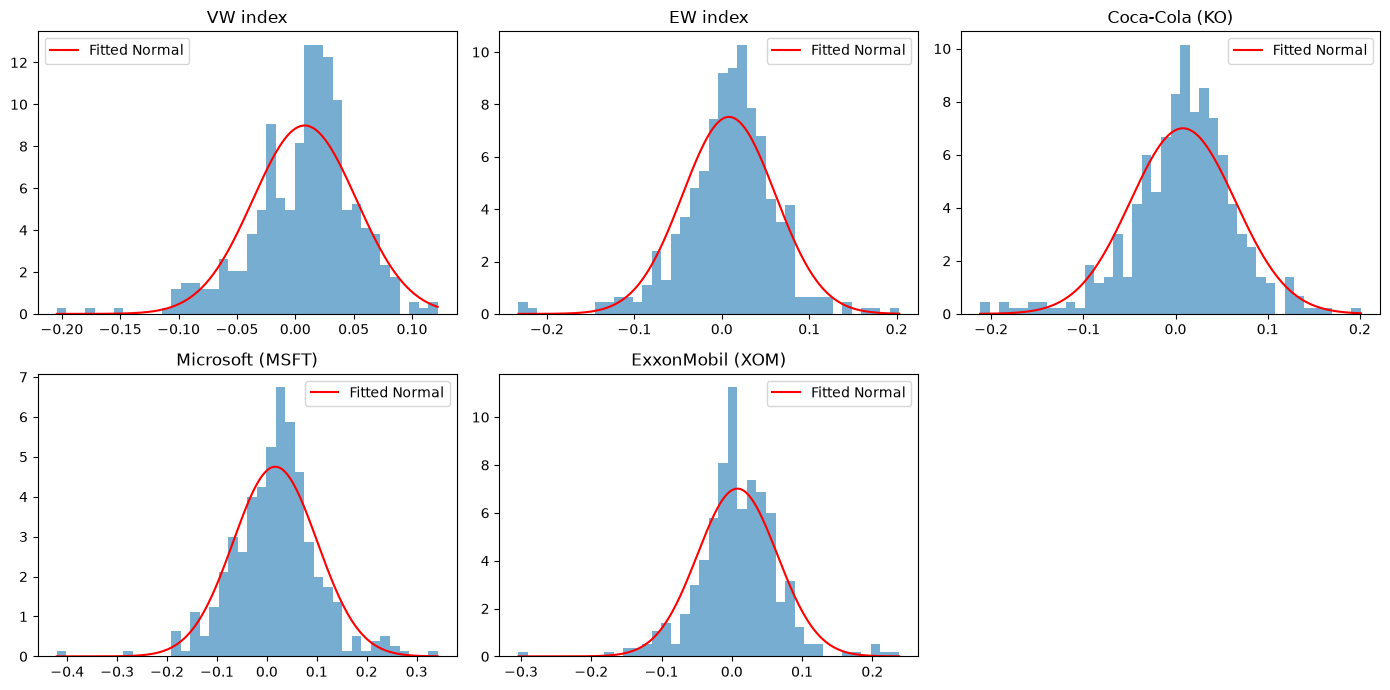

,series,JB statistic,p-value,decision (5%)
0,VW index,106.6334,0.0000,Reject normality
1,EW index,158.9288,0.0000,Reject normality
2,Coca-Cola (KO),83.6492,0.0000,Reject normality
3,Microsoft (MSFT),108.4159,0.0000,Reject normality
4,ExxonMobil (XOM),234.3667,0.0000,Reject normality


In [9]:
# Histogram (density scale) with a Normal curve using the sample mean and std. dev.
fig, axs = plt.subplots(2, 3, figsize=(14, 7))
axs = axs.ravel()
for ax, c in zip(axs, cols):
    x = lr[c]
    grid = np.linspace(x.min(), x.max(), 300)
    ax.hist(x, bins=40, density=True, alpha=.6)
    ax.plot(grid, stats.norm.pdf(grid, x.mean(), x.std()), "r", label="Fitted Normal")
    ax.set_title(names[c])
    ax.legend()
axs[-1].axis("off")                                    # 5 plots, 6 slots
fig.tight_layout()
fig.savefig("figs/q1h_hist.png", dpi=130)
plt.show()

# Jarque-Bera: H0 = skewness 0 and excess kurtosis 0 (i.e. Normal)
rows = []
for c in cols:
    jb, p, skew, kurt = jarque_bera(lr[c])
    rows.append([names[c], jb, p, "Reject normality" if p < .05 else "Do not reject"])
pd.DataFrame(rows, columns=["series", "JB statistic", "p-value", "decision (5%)"])

#### (i) CAPM regressions

$r_{i,t} = \alpha_i + \beta_i\, r_{VW,t} + \varepsilon_{i,t}$  (risk-free rate = 0)

In [10]:
X = sm.add_constant(lr["VWRET"])                       # intercept (alpha) + market return (beta)
capm = {}
for c in ["COCACOLA", "MICROSOFT", "EXXON"]:
    capm[c] = sm.OLS(lr[c], X).fit()
    m = capm[c]
    print(f"--- {names[c]}   (R² = {m.rsquared:.3f}) ---")
    display(pd.DataFrame({"coef": m.params, "std err": m.bse, "t": m.tvalues,
                          "p-value": m.pvalues}).rename(index={"const": "alpha", "VWRET": "beta"}))

--- Coca-Cola (KO)   (R² = 0.190) ---


,coef,std err,t,p-value
alpha,0.0036,0.0025,1.3963,0.1634
beta,0.5601,0.0566,9.9024,0.0000


--- Microsoft (MSFT)   (R² = 0.331) ---


,coef,std err,t,p-value
alpha,0.0080,0.0034,2.3518,0.0191
beta,1.0886,0.0757,14.3765,0.0000


--- ExxonMobil (XOM)   (R² = 0.239) ---


,coef,std err,t,p-value
alpha,0.0029,0.0025,1.1780,0.2395
beta,0.6267,0.0547,11.4526,0.0000


## Question 2 – Household wealth (pension data)

#### (a) Import the data

In [11]:
pen = pd.read_stata("data/pension.dta")
print(pen.shape)
pen.head()

(9275, 11)


,e401k,inc,marr,male,age,fsize,nettfa,p401k,pira,incsq,agesq
0,0,13.1700,0,0,40,1,4.5750,0,1,173.4489,1600
1,1,61.2300,0,1,35,1,154.0000,1,0,"3,749.1128",1225
2,0,12.8580,1,0,44,2,0.0000,0,0,165.3282,1936
3,0,98.8800,1,1,44,2,21.8000,0,0,"9,777.2539",1936
4,0,22.6140,0,0,53,1,18.4500,0,0,511.3930,2809


#### (b) Single-person households

In [12]:
single = pen[pen["fsize"] == 1].copy()                 # family size of 1
print(f"{len(single)} single-person households = {len(single) / len(pen):.2%} of {len(pen)}")

2017 single-person households = 21.75% of 9275


#### (c) Model (1) on singles

$nettfa = \beta_0 + \beta_1\, inc + \beta_2\, age + u$

In [13]:
m1 = smf.ols("nettfa ~ inc + age", data=single).fit()
print(m1.summary().tables[1])
print(f"R² = {m1.rsquared:.4f}, N = {int(m1.nobs)}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -43.0398      4.080    -10.548      0.000     -51.042     -35.038
inc            0.7993      0.060     13.382      0.000       0.682       0.916
age            0.8427      0.092      9.158      0.000       0.662       1.023
R² = 0.1193, N = 2017


#### (d) Meaning of the intercept

In [14]:
# The intercept is the predicted nettfa at inc = 0 and age = 0: outside the data range
print("intercept:", round(m1.params["Intercept"], 3))
single[["inc", "age"]].describe().loc[["min", "max"]]

intercept: -43.04


,inc,age
min,10.0080,25.0000
max,143.0670,64.0000


#### (e) $H_0: \beta_2 = 1$ vs $H_1: \beta_2 < 1$ (one-sided)

In [15]:
# t = (estimate - hypothesised value) / standard error
t_stat = (m1.params["age"] - 1) / m1.bse["age"]
p_one = stats.t.cdf(t_stat, m1.df_resid)               # left-tail probability
print(f"t = {t_stat:.3f}, one-sided p-value = {p_one:.4f} ->", "reject H0" if p_one < .05 else "do not reject H0")

t = -1.710, one-sided p-value = 0.0437 -> reject H0


#### (f) Same test, two-sided alternative $H_1: \beta_2 \neq 1$

In [16]:
p_two = 2 * stats.t.sf(abs(t_stat), m1.df_resid)       # both tails
print(f"t = {t_stat:.3f}, two-sided p-value = {p_two:.4f} ->", "reject H0" if p_two < .05 else "do not reject H0")

# Cross-check with statsmodels
m1.t_test("age = 1")

t = -1.710, two-sided p-value = 0.0874 -> do not reject H0


<class 'statsmodels.stats.contrast.ContrastResults'>
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.8427      0.092     -1.710      0.087       0.662       1.023

#### (g) Omitting age

In [17]:
m2 = smf.ols("nettfa ~ inc", data=single).fit()
print(f"inc coefficient without age: {m2.params['inc']:.4f}   with age: {m1.params['inc']:.4f}")
print(f"corr(inc, age) among singles: {single['inc'].corr(single['age']):.4f}")

# Omitted-variable-bias formula: b_short = b1 + b2 * delta, delta = slope of age on inc
delta = smf.ols("age ~ inc", data=single).fit().params["inc"]
print(f"b1 + b2*delta = {m1.params['inc'] + m1.params['age'] * delta:.4f}  (equals the short-regression coefficient)")

inc coefficient without age: 0.8207   with age: 0.7993
corr(inc, age) among singles: 0.0391
b1 + b2*delta = 0.8207  (equals the short-regression coefficient)


#### (h) Model (2) on the full sample

$nettfa = \beta_0 + \beta_1 inc + \beta_2 age + \beta_3 inc^2 + \beta_4 age^2 + \beta_5 fsize + u$

In [18]:
pen["inc2"] = pen["inc"] ** 2
pen["age2"] = pen["age"] ** 2
formula2 = "nettfa ~ inc + age + inc2 + age2 + fsize"
m3 = smf.ols(formula2, data=pen).fit()
print(m3.summary().tables[1])
print(f"R² = {m3.rsquared:.4f}, N = {int(m3.nobs)}")

# Marginal effects: d nettfa / d age = b2 + 2*b4*age ;  d nettfa / d inc = b1 + 2*b3*inc
b = m3.params
print(f"marginal effect of income at mean income: {b['inc'] + 2 * b['inc2'] * pen['inc'].mean():.4f}")
print(f"age effect positive for age < {-b['age'] / (2 * b['age2']):.0f}  (sample ages: {pen['age'].min()}-{pen['age'].max()})")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -30.3381      3.100     -9.785      0.000     -36.416     -24.261
inc           -0.1578      0.073     -2.162      0.031      -0.301      -0.015
age            1.0209      0.058     17.536      0.000       0.907       1.135
inc2           0.0096      0.001     16.500      0.000       0.008       0.011
age2          -0.0002      0.008     -0.019      0.985      -0.016       0.016
fsize         -2.3431      0.394     -5.948      0.000      -3.115      -1.571
R² = 0.1971, N = 9275
marginal effect of income at mean income: 0.5982
age effect positive for age < 3242  (sample ages: 25-64)


#### (i) F-test of $H_0: \beta_3 = \beta_4 = 0$

In [19]:
m3.f_test("inc2 = 0, age2 = 0")

<class 'statsmodels.stats.contrast.ContrastResults'>
<F test: F=136.12257338029448, p=5.423346691354578e-59, df_denom=9.27e+03, df_num=2>

#### (j) Rescaling income by 100

In [20]:
# Rescale inc and (consistently) its square, then re-estimate
pen["inc_s"] = pen["inc"] / 100
pen["inc_s2"] = pen["inc_s"] ** 2
m4 = smf.ols("nettfa ~ inc_s + age + inc_s2 + age2 + fsize", data=pen).fit()
print(m4.summary().tables[1])
print(f"t-stat of inc: original {m3.tvalues['inc']:.4f} | rescaled {m4.tvalues['inc_s']:.4f}")
print(f"R²: original {m3.rsquared:.6f} | rescaled {m4.rsquared:.6f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -30.3381      3.100     -9.785      0.000     -36.416     -24.261
inc_s        -15.7842      7.300     -2.162      0.031     -30.094      -1.474
age            1.0209      0.058     17.536      0.000       0.907       1.135
inc_s2        96.2958      5.836     16.500      0.000      84.855     107.736
age2          -0.0002      0.008     -0.019      0.985      -0.016       0.016
fsize         -2.3431      0.394     -5.948      0.000      -3.115      -1.571
t-stat of inc: original -2.1622 | rescaled -2.1622
R²: original 0.197058 | rescaled 0.197058


#### (k) Heteroskedasticity-robust (White) standard errors

In [21]:
# Same coefficients, different standard errors (HC1 = White with small-sample correction)
m5 = smf.ols(formula2, data=pen).fit(cov_type="HC1")
pd.DataFrame({"coef": m3.params,
              "se (OLS)": m3.bse, "t (OLS)": m3.tvalues, "p (OLS)": m3.pvalues,
              "se (robust)": m5.bse, "t (robust)": m5.tvalues, "p (robust)": m5.pvalues})

,coef,se (OLS),t (OLS),p (OLS),se (robust),t (robust),p (robust)
Intercept,-30.3381,3.1005,-9.7850,0.0000,5.2757,-5.7506,0.0000
inc,-0.1578,0.0730,-2.1622,0.0306,0.2846,-0.5546,0.5791
age,1.0209,0.0582,17.5356,0.0000,0.0637,16.0298,0.0000
inc2,0.0096,0.0006,16.4996,0.0000,0.0029,3.3459,0.0008
age2,-0.0002,0.0081,-0.0194,0.9845,0.0082,-0.0192,0.9847
fsize,-2.3431,0.3939,-5.9481,0.0000,0.3111,-7.5322,0.0000


#### (l) Standardised variables in model (1)

In [22]:
# z-score every variable (mean 0, sd 1) -> coefficients read in standard-deviation units
cols_z = ["nettfa", "inc", "age"]
z = (single[cols_z] - single[cols_z].mean()) / single[cols_z].std()
m6 = smf.ols("nettfa ~ inc + age", data=z).fit()
print(m6.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -2.089e-08      0.021  -9.99e-07      1.000      -0.041       0.041
inc            0.2800      0.021     13.382      0.000       0.239       0.321
age            0.1916      0.021      9.158      0.000       0.151       0.233
